# 16 · Predicting the starting XI

**Question: who is likely to start?**

$$ P(Start_i \mid Match) $$

for every candidate, then a lineup that respects positions:

```
Player probabilities → Formation → Position constraints → Optimisation → Starting XI
```

**Candidates** (D-025): the published matchday squad where it is recorded
(every match from 2015/16), otherwise every player who appeared in the
previous 60 days. **Features** are all pre-match (`player_fixture` table,
notebook 11): selection history, minutes and workload, form rating, last
season's BIPR, rank within the position group, and match context.
**Training** is walk-forward by season. Choices are made on 2008/09-2013/14
and reported on 2014/15-2020/21, as for the outcome model.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from barca import config
from barca.data import store
from barca.models import lineup
from barca.visualization import pitch as vp
from barca.visualization import style

warnings.filterwarnings("ignore")
style.apply()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(3)

pf = store.features("player_fixture")
prod = pl.read_parquet(config.MODELS / "lineup" / "predictions.parquet")
hist = lineup.xi_history(store.tactics(), store.matches())
actual = store.appearances().filter(pl.col("team") == "Barcelona", pl.col("started")).select("match_id", "player_id")
DEV = [f"{y}/{y + 1}" for y in range(2008, 2014)]
HOLD = [f"{y}/{y + 1}" for y in range(2014, 2021)]
print(f"candidate rows: {pf.height:,} · fixtures with predictions: {prod['date'].n_unique()}")

candidate rows: 11,417 · fixtures with predictions: 485


## 1. Start probabilities

LightGBM against a regularised logistic regression on the same features,
walk-forward:

In [2]:
lab = prod.filter(pl.col("started").is_not_null())
y, p = lab["started"].cast(pl.Int8).to_numpy(), lab["p_start"].to_numpy()
rows = [{"model": "lightgbm", "auc": roc_auc_score(y, p), "log_loss": log_loss(y, p)}]
data_ = lineup.labelled(pf)
ps, ys = [], []
for season in DEV + HOLD:
    tr, te = data_.filter(pl.col("season") < season), data_.filter(pl.col("season") == season)
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
    m.fit(lineup.matrix(tr), tr["started"].to_numpy())
    ps.append(m.predict_proba(lineup.matrix(te))[:, 1])
    ys.append(te["started"].to_numpy())
rows.append({"model": "logistic", "auc": roc_auc_score(np.concatenate(ys), np.concatenate(ps)),
             "log_loss": log_loss(np.concatenate(ys), np.concatenate(ps))})
rows.append({"model": "base rate", "auc": 0.5, "log_loss": log_loss(y, np.full_like(p, y.mean()))})
pl.DataFrame(rows)

model,auc,log_loss
str,f64,f64
"""lightgbm""",0.828,0.502
"""logistic""",0.822,0.511
"""base rate""",0.500,0.683


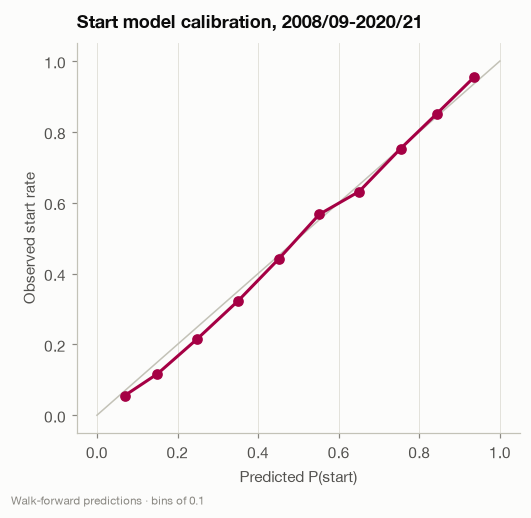

In [3]:
bins = np.linspace(0, 1, 11)
idx = np.clip(np.digitize(p, bins) - 1, 0, 9)
cal = pl.DataFrame({"bin": idx, "p": p, "y": y}).group_by("bin").agg(pl.col("p").mean(), pl.col("y").mean(), pl.len()).sort("bin")
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], color=style.AXIS, lw=1)
ax.plot(cal["p"], cal["y"], color=style.BARCA, marker="o", lw=2)
ax.set_xlabel("Predicted P(start)")
ax.set_ylabel("Observed start rate")
ax.set_title("Start model calibration, 2008/09-2020/21")
ax.grid(axis="both")
style.caption(ax, "Walk-forward predictions · bins of 0.1")
style.savefig(fig, "16_start_calibration")
plt.show()

LightGBM separates starters from non-starters well (AUC ≈ 0.83) and edges
out the logistic model (0.822). Its probabilities are close to calibrated. When it says
80%, the player starts about 80% of the time, which is what lets the app
show "Start probability 87%" honestly.

## 2. What drives selection?

In [4]:
from barca.models.lineup import StartModel  # noqa: E402
import shap  # noqa: E402

model = StartModel().fit(data_.filter(pl.col("season") < "2020/2021"))
X = lineup.matrix(data_.filter(pl.col("season") == "2020/2021"))
sv = np.asarray(shap.TreeExplainer(model.model_).shap_values(X))
if sv.ndim == 3:
    sv = sv[1] if sv.shape[0] == 2 else sv[..., 1]
imp = pl.DataFrame({"feature": lineup.FEATURES, "mean_abs_shap": np.abs(sv).mean(axis=0)}).sort("mean_abs_shap", descending=True)
imp.head(12)

feature,mean_abs_shap
str,f64
"""season_start_share""",0.594
"""minutes_last5""",0.495
"""squad_known""",0.153
"""starts_last10""",0.127
"""form_rating""",0.122
"""minutes_14d""",0.108
"""workload_index""",0.108
"""days_since_last_start""",0.107
"""prev_season_overall""",0.099


Selection is mostly **continuity**: the season's start share and minutes
in the last five matches dominate, followed by whether the squad is known,
recent starts and time since the last start. Form rating and last season's
rating add something. The workload index ranks seventh, far behind the
continuity features, consistent with notebook 11's finding that observed league workload does not
predict rotation.

## 3. Formations

In [5]:
forms = (
    hist.select("match_id", "date", "formation").unique("match_id")
    .join(store.matches().select("match_id", "barca_era"), on="match_id")
    .group_by("barca_era", "formation").agg(pl.len().alias("n"))
    .with_columns((pl.col("n") / pl.col("n").sum().over("barca_era")).alias("share"))
    .sort(["barca_era", "n"], descending=[False, True])
    .group_by("barca_era", maintain_order=True).head(2)
)
forms

barca_era,formation,n,share
str,str,u32,f64
"""Ernesto Valverde""","""433""",44,0.524
"""Ernesto Valverde""","""442""",24,0.286
"""Frank Rijkaard""","""433""",74,0.961
"""Frank Rijkaard""","""343""",3,0.039
"""Gerardo Martino""","""433""",30,0.968
"""Gerardo Martino""","""41212""",1,0.032
"""Luis Enrique""","""433""",99,0.892
"""Luis Enrique""","""343""",6,0.054
"""Pep Guardiola""","""433""",119,0.862


In [6]:
fx = prod.select("match_id", "date", "formation").unique("match_id").drop_nulls("match_id")
real = hist.select("match_id", pl.col("formation").alias("actual_formation")).unique("match_id")
fa = fx.join(real, on="match_id")
print(f"expected formation (most used in last 5) matches the actual one in {(fa['formation'] == fa['actual_formation']).mean():.0%} of matches")

expected formation (most used in last 5) matches the actual one in 78% of matches


4-3-3 is the house formation for most eras. Exceptions: a 4-4-2 under
Valverde, a diamond (4-1-2-1-2) under Setién, and a 4-2-3-1 or back three
under Koeman. Predicting the formation as "the
most used in the last five" is right most of the time. When a coach
changes shape, the XI model still places players in sensible positions
because assignment works on position *families*, with a small preference
for each player's usual flank (86% of wide slots go to a player on his
usual side, against 57% without it).

## 4. From probabilities to a lineup

The assignment maximises $\log P(start) + \lambda \log(eligibility)$ over the
formation's eleven slots. λ trades probability against positional fit and
was chosen on the development seasons:

In [7]:
dev_pred, _ = lineup.walk_forward(pf, DEV)
dev_pred = dev_pred.filter(pl.col("match_id").is_not_null())
lam_rows = []
for lam in (0.1, 0.25, 0.5, 1.0, 2.0):
    lineup.LAMBDA = lam
    acc = lineup.xi_accuracy(lineup.predict_lineups(dev_pred, hist), actual)
    lam_rows.append({"lambda": lam, "mean_correct_dev": acc["correct"].mean()})
lineup.LAMBDA = 0.25
pl.DataFrame(lam_rows)

lambda,mean_correct_dev
f64,f64
0.100,8.297
0.250,8.267
0.500,8.200
1.000,8.087
2.000,7.779


A light positional weight is best: strong weights force players into
"their" slot even when the coach clearly intends otherwise. λ = 0.25 is
used. It is essentially as accurate as the best value and keeps the
structure a lineup needs.

## 5. Holdout results against baselines

In [8]:
hold = prod.filter(pl.col("season").is_in(HOLD), pl.col("match_id").is_not_null())


def score(frame: pl.DataFrame, flag: str) -> dict:
    a = lineup.xi_accuracy(frame, actual, flag)
    return {"mean_correct": a["correct"].mean(), "all_11": (a["correct"] == 11).mean(),
            "at_least_9": (a["correct"] >= 9).mean(), "fixtures": a.height, "avg_picked": a["n_picked"].mean()}


variants = {
    "Model + formation + positions (production)": ("in_xi", hold),
    "Model: 11 highest probabilities": ("f", hold.with_columns((pl.col("p_start").rank("ordinal", descending=True).over("match_id") <= 11).alias("f"))),
    "Baseline: most regular starters (last 10)": ("f", hold.with_columns((pl.col("starts_last10").rank("ordinal", descending=True).over("match_id") <= 11).alias("f"))),
    "Baseline: same XI as last match": ("f", hold.with_columns((pl.col("started_last1") == 1).alias("f"))),
}
res = pl.DataFrame([{"approach": k, **score(frame, flag)} for k, (flag, frame) in variants.items()])
res

approach,mean_correct,all_11,at_least_9,fixtures,avg_picked
str,f64,f64,f64,i64,f64
"""Model + formation + positions …",8.992,0.117,0.661,248,11.000
"""Model: 11 highest probabilitie…",8.968,0.085,0.669,248,11.000
"""Baseline: most regular starter…",8.835,0.069,0.649,248,11.000
"""Baseline: same XI as last matc…",7.778,0.032,0.367,248,10.040


In [9]:
top11 = variants["Model: 11 highest probabilities"][1].filter(pl.col("f")).group_by("match_id").agg(
    (pl.col("position_family") == "GK").sum().alias("goalkeepers"))
prodk = hold.filter(pl.col("in_xi")).group_by("match_id").agg((pl.col("slot") == "Goalkeeper").sum().alias("goalkeepers"))
print("lineups with exactly one goalkeeper: production",
      f"{(prodk['goalkeepers'] == 1).mean():.0%}", "· top-11 by probability", f"{(top11['goalkeepers'] == 1).mean():.1%}")

lineups with exactly one goalkeeper: production 100% · top-11 by probability 95.6%


In [10]:
by_squad = hold.join(hold.group_by("match_id").agg(pl.col("squad_known").first().alias("known")), on="match_id")
pl.DataFrame([
    {"squad published": k, **score(by_squad.filter(pl.col("known") == k), "in_xi")} for k in (True, False)
]).select("squad published", "fixtures", "mean_correct", "at_least_9")

squad published,fixtures,mean_correct,at_least_9
bool,i64,f64,f64
true,237,9.017,0.671
false,11,8.455,0.455


On the holdout seasons the production approach gets **about 9 of 11
starters right** (8.99). That is clearly ahead of "same XI as last match"
(7.78) and ahead of "most regular starters" (8.84), and it predicts the
entire XI correctly in about one match in eight. Taking the 11 highest
probabilities is about as accurate (8.97) but produces an impossible lineup
(no goalkeeper or two) in about 4% of matches. The constrained version
always fields exactly one. Knowing the published squad helps (9.0 vs 8.5
correct), though only 11 holdout fixtures lack one.

## 6. One lineup, predicted and actual

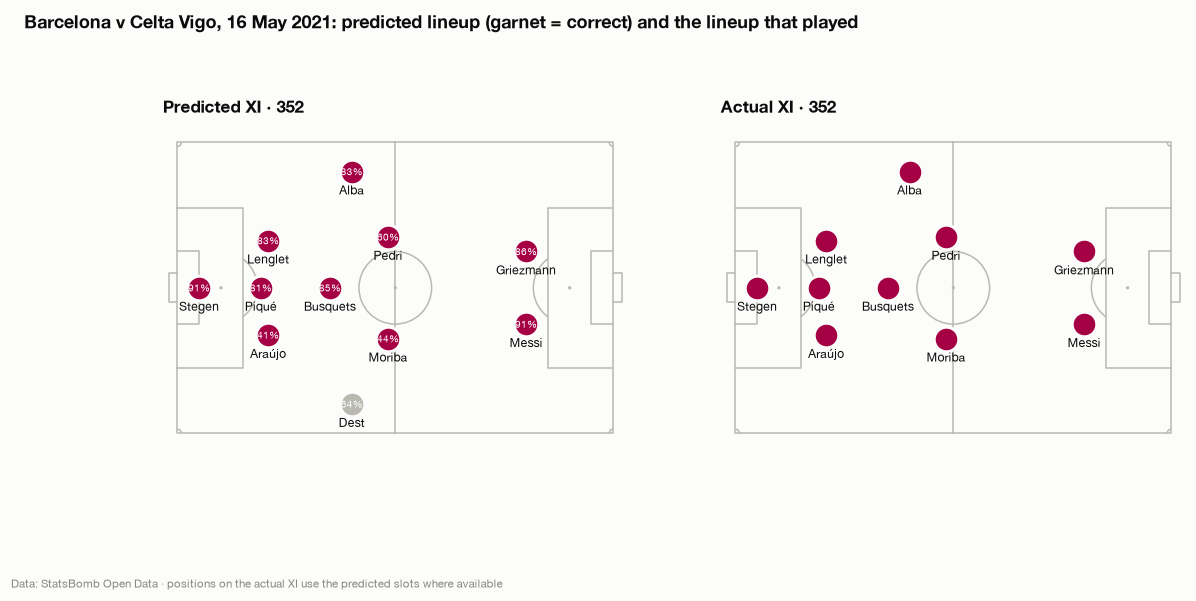

[
 {
  "feature": "season_start_share",
  "text": "Started 35% of matches this season",
  "shap": -0.398
 },
 {
  "feature": "season_matches_before",
  "text": "34 matches into the season",
  "shap": -0.171
 },
 {
  "feature": "days_since_last_start",
  "text": "5 days since last start",
  "shap": -0.17
 },
 {
  "feature": "minutes_14d",
  "text": "187 minutes in the last 14 days",
  "shap": 0.164
 }
]


In [11]:
fixture = prod.filter(pl.col("date") == pl.date(2021, 5, 16))
opp = fixture["opponent"][0]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
p_ = vp.pitch()
for ax, (title, frame) in zip(axes, [("Predicted XI", fixture.filter(pl.col("in_xi"))),
                                      ("Actual XI", fixture.filter(pl.col("started").fill_null(False)))], strict=True):
    p_.draw(ax=ax)
    for r in frame.iter_rows(named=True):
        if r["slot_x"] is None:
            continue
        correct = bool(r["started"]) if title == "Predicted XI" else bool(r["in_xi"])
        colour = style.BARCA if correct else style.NEUTRAL
        p_.scatter(r["slot_x"], r["slot_y"], ax=ax, s=260, color=colour, edgecolor=style.SURFACE, linewidth=2, zorder=3)
        ax.annotate(r["display_name"].split()[-1], (r["slot_x"], r["slot_y"]), xytext=(0, -15),
                    textcoords="offset points", ha="center", fontsize=8, color=style.INK)
        if title == "Predicted XI":
            ax.annotate(f"{r['p_start']:.0%}", (r["slot_x"], r["slot_y"]), ha="center", va="center", fontsize=6.5,
                        color="white", zorder=4)
    ax.set_title(f"{title} · {fixture['formation'][0]}", fontsize=11)
fig.suptitle(f"Barcelona v {opp}, 16 May 2021: predicted lineup (garnet = correct) and the lineup that played",
             fontsize=12, fontweight="bold", x=0.02, ha="left")
style.caption(axes[0], style.STATSBOMB_CREDIT + " · positions on the actual XI use the predicted slots where available")
style.savefig(fig, "16_predicted_xi")
plt.show()
print(json.dumps(json.loads(fixture.filter(pl.col("in_xi")).sort("p_start")["reasons"][0]), indent=1))

Ten of the eleven predicted starters started. The one miss: the model
preferred Dest (64%) to Dembélé (46%), and Dembélé started. The printed
reasons for the least certain pick (Araújo, 41%) are the kind of
explanation the app shows next to each player ("Why selected?"): a low
season start share pulls him down, recent minutes pull him up.

## Findings

1. **Start probabilities are accurate and calibrated** (AUC ≈ 0.83),
   driven mainly by continuity: season start share, recent minutes and
   recent starts.
2. **Structured assignment keeps lineups valid** (always one goalkeeper, a
   plausible back line) at no cost in accuracy.
3. **About 9 of 11 starters correct** on the holdout seasons, ahead of both
   baselines. With the published squad it rises further.
4. **Workload plays a small role** in selection, consistent with notebook 11.

Next: the application database and API, then the frontend.